# AIRBNB — Báo cáo hiểu sâu dữ liệu

**Phạm vi: EDA trên dữ liệu gốc; chưa feature engineering, chưa huấn luyện mô hình.**

Báo cáo có từ điển dữ liệu, kiểm tra chất lượng/khóa/nhãn, thống kê theo nhóm, thời gian và giới hạn suy rộng. Các kết quả được tính lại từ CSV; bản đọc nhanh nằm ở `reports/AIRBNB/README.md`.

Mọi phân nhóm tạm thời chỉ phục vụ mô tả, không tạo tập feature. Chạy tất cả các cell theo thứ tự; cell đầu quét dữ liệu đầy đủ nên có thể mất vài phút với Expedia.

In [1]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'data' / 'raw').is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError('Không tìm thấy data/raw; hãy mở notebook trong dự án Propensity.')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from scripts import build_descriptive_reports as eda
importlib.reload(eda)
report = eda.build_report('AIRBNB', PROJECT_ROOT)
print('Đã tính lại từ CSV raw; số chính:', report.facts)
print('Chỉ xuất báo cáo, metadata và biểu đồ; không tạo dữ liệu mô hình.')

Đã tính lại từ CSV raw; số chính: {'rows': 213451, 'columns': 16, 'positive': 88908, 'rate': 0.4165265095970504, 'sessions': 10567737, 'session_users': 135483, 'train_session_users': 73815, 'test_session_users': 61668, 'test_rows': 62096, 'sessions_missing_ids': 34496}
Chỉ xuất báo cáo, metadata và biểu đồ; không tạo dữ liệu mô hình.


## 1. Bối cảnh, đơn vị quan sát và phạm vi nhãn

In [2]:
eda.show_section(report, 'scope')

Train gồm **213,451 người dùng, 16 cột**, test gồm **62,096 người dùng, 15 cột**. Nhãn gốc là `country_destination` với 12 giá trị, gồm `NDF` và 11 điểm đến/nhóm điểm đến còn lại. Đối với propensity nhị phân, báo cáo chỉ thống kê hành vi **có booking được ghi nhận** khi nhãn khác NDF; không tạo tập nhãn huấn luyện mới.

Mục tiêu gốc là dự đoán điểm đến booking đầu, không trực tiếp cung cấp nhãn booking trong 30/60/90 ngày. `NDF` nghĩa không có booking theo nhãn của bộ dữ liệu; không khẳng định người dùng sẽ không bao giờ book. Chưa xác minh được ngày kết thúc theo dõi cho từng người dùng và độ trưởng thành nhãn ở mỗi cohort.

[Mô tả cuộc thi Airbnb New User Bookings](https://www.kaggle.com/c/airbnb-recruiting-new-user-bookings/data) nêu người dùng trong tập đến từ Mỹ. Vì vậy tính đại diện về địa lý, thời kỳ và sản phẩm có giới hạn. Test công khai không có nhãn để tính chất lượng dự đoán hoặc so sánh booking rate với train.

**Danh mục đầy đủ; submission chỉ là định dạng kết quả, không phải dữ liệu người dùng bổ sung**

,file,data_lines,columns,bytes,sha256
0,age_gender_bkts.csv,420,5,11905,ca101ff0d68112ac43083e5868ccf643a8701ede4dd0ea...
1,countries.csv,10,7,632,f6bc346fd3c51a237448860c9c77c16db2672d8e4799af...
2,sample_submission_NDF.csv,62096,2,931451,9cd8b164121586b8940ff1666dffce7fd44453628c0e44...
3,sessions.csv,10567737,6,631646292,63d4a31cd7202468b120b6e88df4389f4e0bc0188a4ea6...
4,test_users.csv,62096,15,6763170,17b25cbae6f3f6c95ff553ac108f145f0e3f0873bdae0c...
5,train_users_2.csv,213451,16,24853881,1d57dabe8b06534e51f86520ce6a66b6f67cce1704fb77...


## 2. Từ điển users và quan hệ giữa các bảng

In [3]:
eda.show_section(report, 'dictionary')

`id` là khóa users, ghép một–nhiều với `sessions.user_id`. Cần phân tích users trước và sau ghép mà không làm một người dùng bị nhân thành nhiều quan sát học. `countries` có khóa quốc gia; không ghép bằng điểm đến thật để dự đoán chính nhãn đó. `age_gender_bkts` là thống kê tổng hợp theo bucket/quốc gia/giới tính, không phải thêm 420 khách hàng.

**Schema đầy đủ của train users**

,column,pandas_dtype,distinct_nonnull,missing_n,missing_pct,meaning,role_or_caution
0,id,object,213451,0,0.0000,Định danh người dùng,Khóa ghép sessions.user_id; không phải phép đo
1,date_account_created,object,1634,0,0.0000,Ngày tạo tài khoản,Mốc cohort; không tự xác định horizon nhãn
2,timestamp_first_active,int64,213451,0,0.0000,"Lần hoạt động đầu, dạng YYYYMMDDHHMMSS",Có thể trước ngày tạo tài khoản; cần parse the...
3,date_first_booking,object,1976,124543,58.3473,Ngày booking đầu được ghi nhận,Kết quả; presence tiết lộ nhãn có booking
4,gender,object,4,0,0.0000,Giới tính khai báo,"-unknown- là sentinel, không phải giá trị biết rõ"
5,age,float64,127,87990,41.2226,Tuổi khai báo,Thiếu và giá trị ngoài dải tham chiếu; chưa sử...
6,signup_method,object,3,0,0.0000,Phương thức đăng ký,Biến phân loại
7,signup_flow,int64,17,0,0.0000,Mã luồng/trang đăng ký,Mã phân loại dù pandas đọc số
8,language,object,25,0,0.0000,Ngôn ngữ ưu tiên,Biến phân loại
9,affiliate_channel,object,8,0,0.0000,Kênh marketing liên quan,Không tự chứng minh tác động nhân quả của kênh


**So sánh schema train và test**

,column,in_train,in_test
0,id,True,True
1,date_account_created,True,True
2,timestamp_first_active,True,True
3,date_first_booking,True,True
4,gender,True,True
5,age,True,True
6,signup_method,True,True
7,signup_flow,True,True
8,language,True,True
9,affiliate_channel,True,True


## 3. Chất lượng users, sentinel và rò rỉ nhãn

In [4]:
eda.show_section(report, 'quality')

**Rò rỉ đã kiểm chứng:** presence của `date_first_booking` khớp nhãn có booking ở **100.00%** người dùng train. Không dùng ngày này, hoặc cờ thiếu ngày này, làm đầu vào dự đoán booking đầu. Đây là thiếu theo cấu trúc kết quả, không phải missing cần impute.

Tuổi ngoài [16,100] được gắn cờ cho EDA; đây là **dải tham chiếu**, không phải chính sách hợp lệ đã xác nhận. Giá trị dạng 19xx/20xx có thể là năm sinh nhưng CSV không chứng minh nguyên nhân của từng dòng; không đổi tuổi, xóa người dùng hay thay giá trị. Gender/browser có sentinel cần thống kê riêng với NA.

Ngày hoạt động đầu trước ngày tạo tài khoản được nguồn gốc cho phép vì có thể tìm kiếm trước khi đăng ký. Có **29** dòng ngày booking trước ngày account; đây là câu hỏi về định nghĩa mốc thời gian cần xác minh, không tự động kết luận lỗi rồi loại bỏ.

**Kiểm tra định danh và logic thời gian**

,check,n
0,ID train bị lặp (beyond first),0
1,ID test bị lặp (beyond first),0
2,ID xuất hiện ở cả train và test,0
3,date_first_booking.notna không khớp nhãn có bo...,0
4,date_first_booking có giá trị trong test,0
5,"Tuổi có giá trị nhưng ngoài [16,100] (quy ước ...",2410
6,Booking đầu trước ngày tạo tài khoản,29
7,Hoạt động đầu trước ngày tạo tài khoản,178
8,Ngày account không parse được,0
9,Timestamp hoạt động đầu không parse được,0


**NA và giá trị đặc biệt là các khái niệm khác nhau**

,column,null_n,minus_unknown_n,untracked_n
0,gender,0,95688,0
1,first_browser,0,27266,0
2,first_affiliate_tracked,6065,0,109232


**Ngày booking có/không × nhãn có/không booking**

observed_booking,has_booking_date,False,True
0,False,124543,0
1,True,0,88908


## 4. Nhãn, tuổi và phân phối kênh/thiết bị

Có booking được ghi nhận: **88,908/213,451 (41.65%)**. Nhóm NDF chiếm **58.35%**. Bảng điểm đến trình bày hai mẫu số riêng: toàn bộ người dùng và chỉ người có booking; không nhầm tỷ trọng US trong toàn bộ users với tỷ trọng US trong nhóm đã book.

Độ tuổi được trình bày cả raw và cửa sổ [16,100] để thấy tác động của giá trị cực đoan. Top category có mẫu số là toàn bộ users, kể cả NA. `signup_flow` là mã phân loại; không báo cáo mean của mã như một đặc điểm khách hàng.

**12 nhãn và hai mẫu số**

,country_destination,n,pct_all_users,pct_booked_users
0,NDF,124543,58.3473,NaN
1,US,62376,29.2226,70.1579
2,other,10094,4.7290,11.3533
3,FR,5023,2.3532,5.6497
4,IT,2835,1.3282,3.1887
5,GB,2324,1.0888,2.6139
6,ES,2249,1.0536,2.5296
7,CA,1428,0.6690,1.6062
8,DE,1061,0.4971,1.1934
9,NL,762,0.3570,0.8571


**Tuổi raw và cửa sổ mô tả**

,sample,n,mean,median
0,Toàn bộ age không thiếu,125461,49.6683,34.0000
1,"Chỉ age trong [16,100]; không thay đổi raw",123051,36.5606,34.0000


**Thống kê tuổi raw**

,column,count,mean,std,min,1%,25%,50%,75%,95%,99%,max,missing_pct,skewness
0,age,"125,461.0000",49.6683,155.6666,1.0000,19.0000,28.0000,34.0000,43.0000,64.0000,105.0000,"2,014.0000",41.2226,12.4226


**Phân phối category — top 8/cột**

,column,value,n,pct_all_rows
0,gender,-unknown-,95688,44.8290
1,gender,FEMALE,63041,29.5342
2,gender,MALE,54440,25.5047
3,gender,OTHER,282,0.1321
4,signup_method,basic,152897,71.6310
5,signup_method,facebook,60008,28.1132
6,signup_method,google,546,0.2558
7,signup_flow,0,164739,77.1788
8,signup_flow,25,14659,6.8676
9,signup_flow,12,9329,4.3706


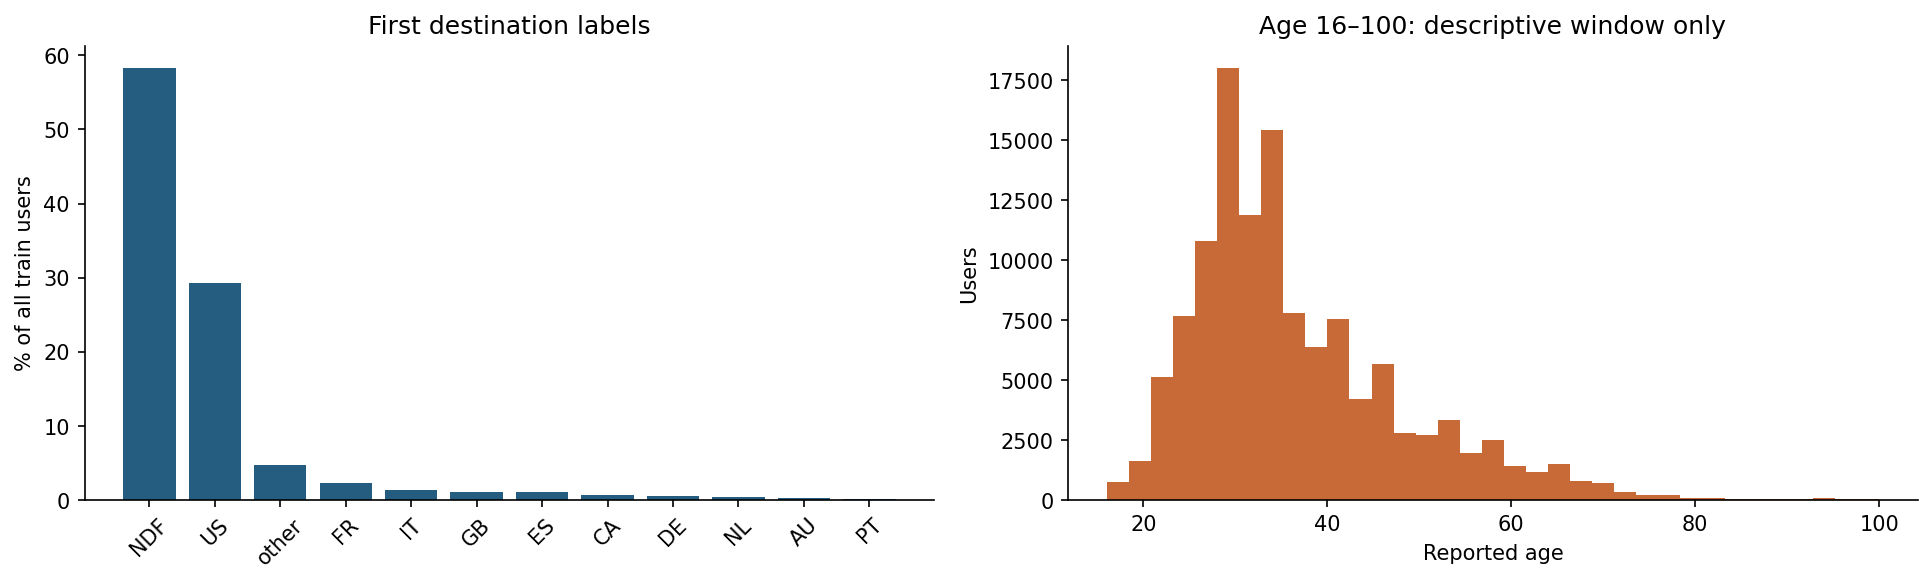

In [5]:
eda.show_section(report, 'distributions')

## 5. Quan hệ giữa hồ sơ đăng ký và nhãn

In [6]:
eda.show_section(report, 'target')

Mỗi quan sát là một user train. Khoảng Wilson 95% chỉ phản ánh bất định nhị thức dưới giả định độc lập; không bao gồm sai lệch chọn mẫu, nhãn chưa trưởng thành hoặc khác thời gian theo dõi. Các nhóm n<100 cần thận trọng. Chênh lệch booking rate giữa kênh/app/thiết bị là liên hệ quan sát, không chứng minh kênh làm tăng booking. Phân nhóm tuổi phục vụ so sánh EDA, không tạo feature.

**Booking được ghi nhận theo gender**

,gender,n,positive,rate_pct,ci95_low_pct,ci95_high_pct,n_under_100
0,-unknown-,95688,29018,30.3256,30.0352,30.6177,False
1,FEMALE,63041,31993,50.7495,50.3592,51.1397,False
2,MALE,54440,27721,50.9203,50.5003,51.3401,False
3,OTHER,282,176,62.4113,56.6271,67.8620,False


**Booking được ghi nhận theo signup_method**

,signup_method,n,positive,rate_pct,ci95_low_pct,ci95_high_pct,n_under_100
0,basic,152897,65051,42.5456,42.2980,42.7936,False
1,facebook,60008,23756,39.5881,39.1975,39.9800,False
2,google,546,101,18.4982,15.4653,21.9712,False


**Booking được ghi nhận theo signup_app**

... (5 outputs left out)

**Booking được ghi nhận theo first_affiliate_tracked**

,first_affiliate_tracked,n,positive,rate_pct,ci95_low_pct,ci95_high_pct,n_under_100
0,untracked,109232,47739,43.7042,43.4103,43.9986,False
1,linked,46287,20102,43.4290,42.9781,43.8811,False
2,omg,43982,16425,37.3448,36.8939,37.7980,False
3,tracked-other,6156,2290,37.1995,36.0004,38.4145,False
4,<MISSING>,6065,1738,28.6562,27.5321,29.8074,False
5,product,1556,542,34.8329,32.5056,37.2349,False
6,marketing,139,63,45.3237,37.2849,53.6141,False
7,local ops,34,9,26.4706,14.6012,43.1171,True


**Tuổi theo nhãn — NA giữ là nhóm riêng**

,reported_age_group,n,positive,rate_pct,ci95_low_pct,ci95_high_pct,n_under_100
0,<MISSING>,87990,20376,23.1572,22.8796,23.4371,False
1,25–34,55694,32054,57.5538,57.1428,57.9637,False
2,35–44,30759,16834,54.7287,54.1719,55.2843,False
3,45–54,14521,7149,49.2321,48.4193,50.0454,False
4,16–24,10770,5425,50.3714,49.4272,51.3154,False
5,55–64,7599,3904,51.3752,50.2510,52.4980,False
6,65–100,3708,1828,49.2988,47.6912,50.9079,False
7,>100,2345,1321,56.3326,54.3165,58.3281,False
8,1–15,65,17,26.1538,17.0182,37.9508,True


## 6. Sessions: độ phủ, khóa ghép và giới hạn thời gian

Đã quét **toàn bộ 10,567,737 sự kiện**, không dùng 500.000 dòng đầu. Có **135,483 user_id khác nhau không thiếu**, gồm **73,815 train** và **61,668 test**; **0 ID** không thuộc cả hai bảng users. Có **34,496 sự kiện thiếu user_id**, không gán được về người dùng.

Độ phủ train **34.58%**, test **99.31%** khác nhau rất mạnh. Bảng cohort cho thấy độ phủ gắn với năm tạo account; không diễn giải không có log thành không có hoạt động. Tỷ lệ thiết bị dưới đây có mẫu số là **sự kiện**, không phải người dùng, nên người hoạt động nhiều có trọng số lớn hơn.

**Giới hạn quan trọng:** sáu cột sessions không có timestamp sự kiện. Không thể chứng minh từ file này rằng toàn bộ log thuộc cửa sổ trước t0/booking. Các tổng theo user chỉ là mô tả để hiểu độ phủ và mức độ lặp; không xuất thành feature và không kết luận predictive signal hợp lệ theo thời gian.

`secs_elapsed` có 10,431,706 giá trị không thiếu; trung bình 19,405.81, min 0.00, max 1,799,977.00; 104,624 giá trị 0 và 0 âm. Không đồng nhất tổng trường này với thời gian hoạt động độc lập liên tục hoặc thời điểm của hành động.

**Schema toàn bảng sessions**

,column,distinct_nonnull,missing_n,missing_pct,meaning,caution
0,user_id,135483,34496,0.3264,ID ghép users.id,Khóa; NA không ghép được
1,action,359,79626,0.7535,Tên hành động,Không có timestamp sự kiện
2,action_type,10,1126204,10.6570,Nhóm hành động,Có NA/sentinel; không suy ra thứ tự thời gian
3,action_detail,155,1126204,10.6570,Chi tiết hành động,Có NA/sentinel
4,device_type,14,0,0.0000,Thiết bị ở sự kiện,Tỷ trọng sự kiện khác tỷ trọng người dùng
5,secs_elapsed,không tính,136031,1.2872,Trường thời lượng theo mô tả nguồn,Không phải timestamp; không dùng để cắt trước/...


**Độ phủ theo tập users**

,population,users,users_with_sessions,coverage_pct
0,train,213451,73815,34.5817
1,test,62096,61668,99.3107


**Độ phủ theo năm account train**

... (5 outputs left out)

**Thiết bị theo toàn bộ sự kiện**

,device_type,events,pct_all_events
0,Mac Desktop,3594286,34.0119
1,Windows Desktop,2658539,25.1571
2,iPhone,2105031,19.9194
3,Android Phone,839637,7.9453
4,iPad Tablet,683414,6.4670
5,Android App Unknown Phone/Tablet,273652,2.5895
6,-unknown-,211279,1.9993
7,Tablet,139886,1.3237
8,Linux Desktop,28373,0.2685
9,Chromebook,22348,0.2115


**Top 20 action theo toàn bộ sự kiện**

,action,events,pct_all_events
0,show,2768278,26.1956
1,index,843699,7.9837
2,search_results,725226,6.8626
3,personalize,706824,6.6885
4,search,536057,5.0726
5,ajax_refresh_subtotal,487744,4.6154
6,update,365130,3.4551
7,similar_listings,364624,3.4504
8,social_connections,339000,3.2079
9,reviews,320591,3.0337


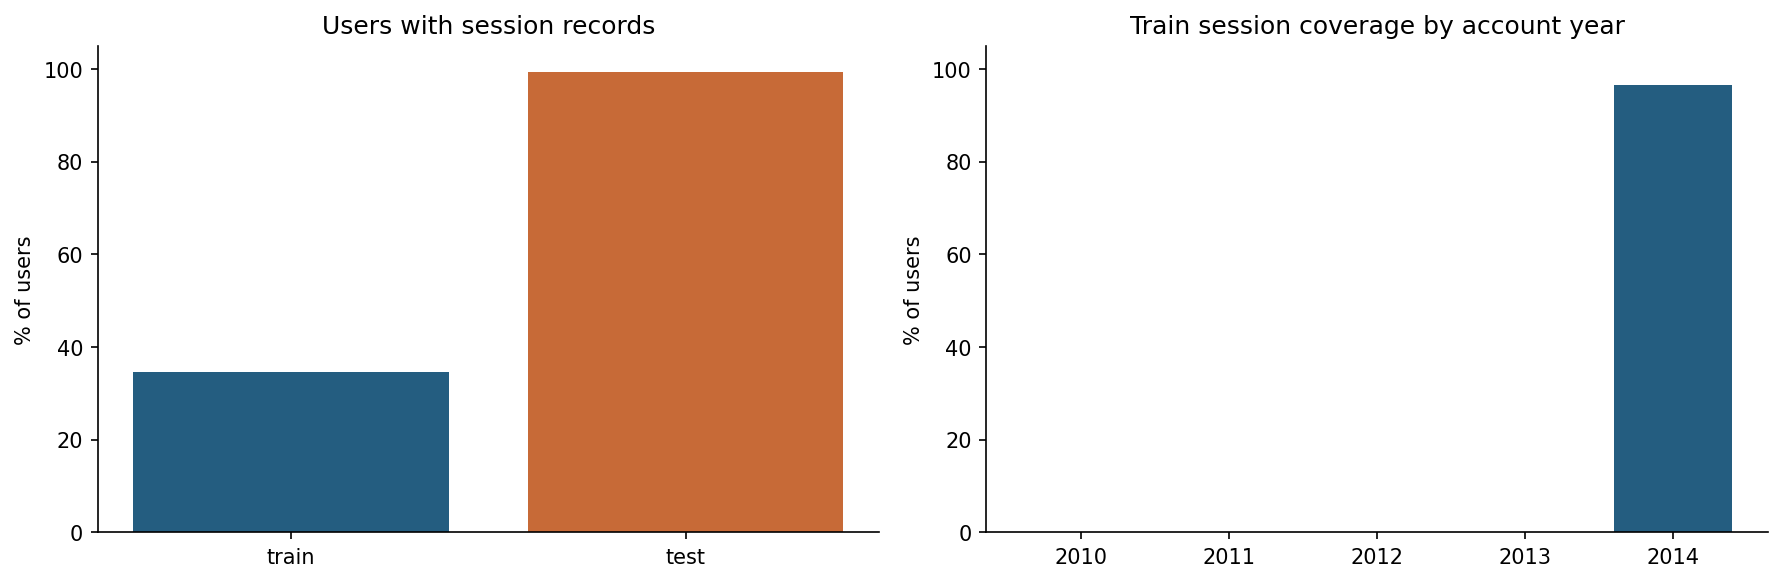

In [7]:
eda.show_section(report, 'sessions')

## 7. Cohort thời gian và thay đổi train–test

Train và test nối tiếp theo ngày tạo account. Đồ thị booking rate theo cohort phản ánh cả thành phần khách và thời gian có cơ hội được quan sát; không kết luận cohort mới kém chất lượng chỉ từ nhãn. Total variation trong [0,1] so sánh phân phối category (kể cả NA); 0 là giống nhau, 1 là không giao nhau. Đây là mô tả drift, không phải ngưỡng tự động loại biến hoặc chọn mô hình.

**Khoảng thời gian account**

,population,account_min,account_max,users
0,train,2010-01-01,2014-06-30,213451
1,test,2014-07-01,2014-09-30,62096


**Cohort theo tháng — toàn bộ train**

,account_month,users,booked,booked_pct
0,2010-01,61,32,52.4590
1,2010-02,102,55,53.9216
2,2010-03,163,106,65.0307
3,2010-04,157,91,57.9618
4,2010-05,227,128,56.3877
5,2010-06,222,109,49.0991
6,2010-07,307,180,58.6319
7,2010-08,312,180,57.6923
8,2010-09,371,218,58.7601
9,2010-10,309,191,61.8123


**Khác biệt category giữa train và test**

,column,total_variation_0_1,test_only_categories,train_missing_pct,test_missing_pct
8,first_device_type,0.3121,0,0.0000,0.0000
9,first_browser,0.2595,3,0.0000,0.0000
7,signup_app,0.2569,0,0.0000,0.0000
2,signup_flow,0.2201,1,0.0000,0.0000
4,affiliate_channel,0.1574,0,0.0000,0.0000
0,gender,0.0959,0,0.0000,0.0000
5,affiliate_provider,0.0920,0,0.0000,0.0000
6,first_affiliate_tracked,0.0798,0,2.8414,0.0322
1,signup_method,0.0419,1,0.0000,0.0000
3,language,0.0137,1,0.0000,0.0000


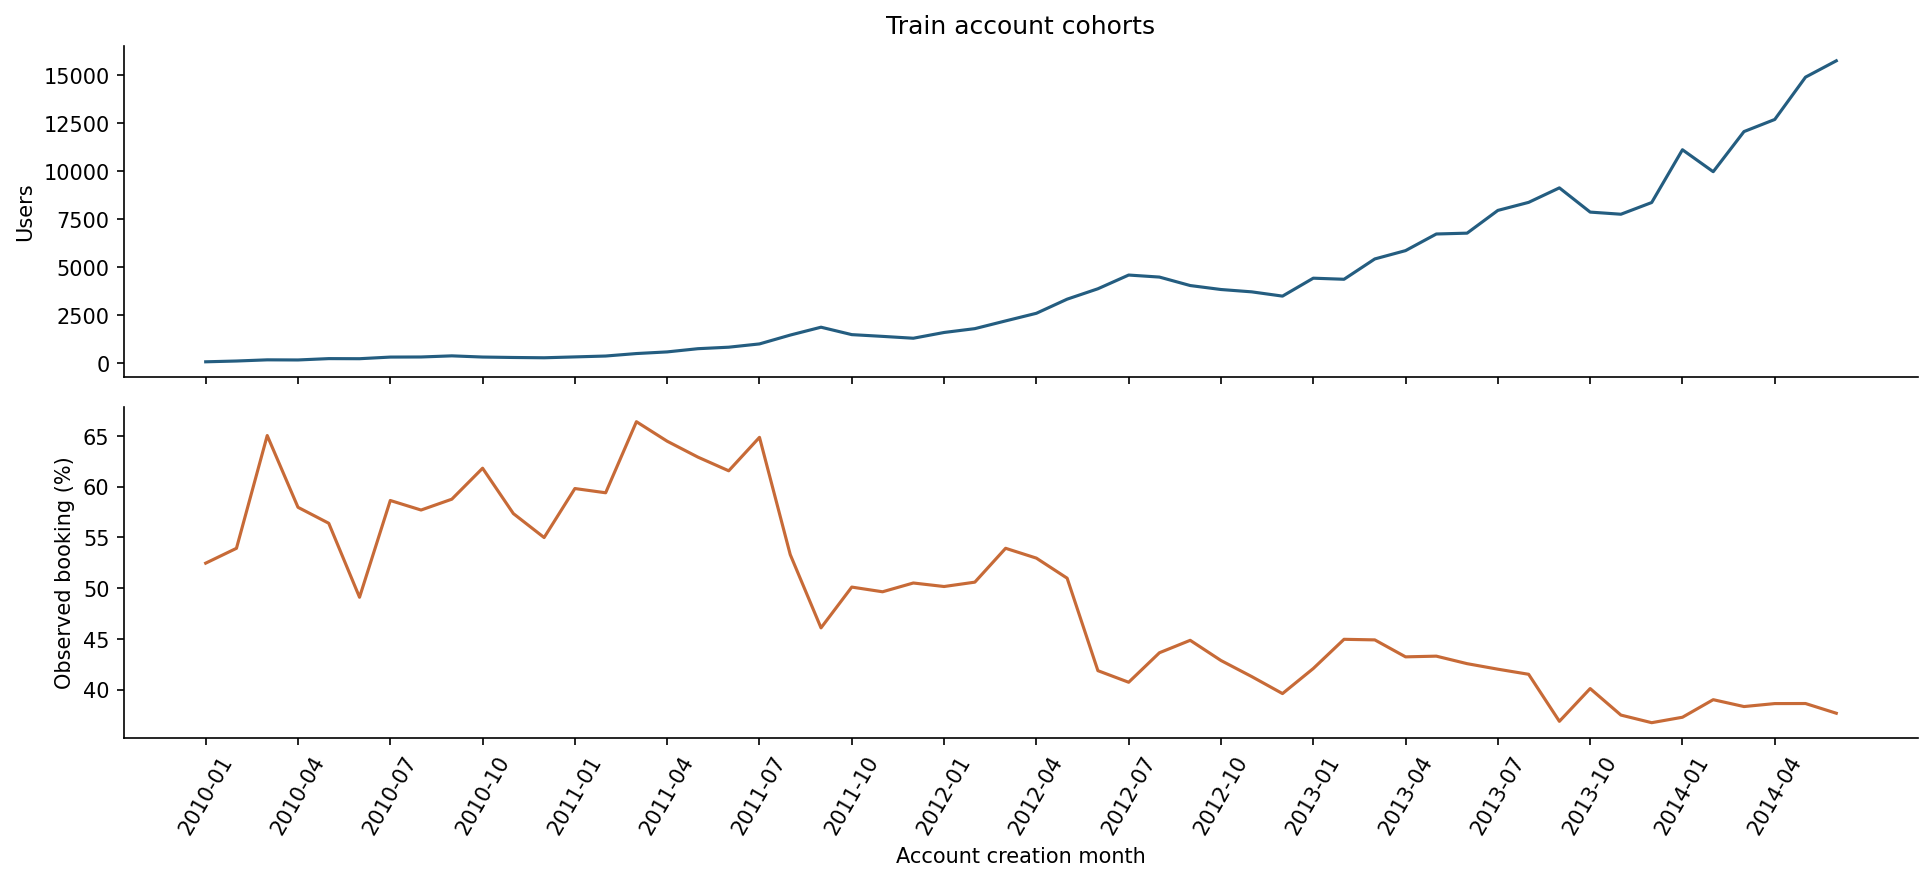

In [8]:
eda.show_section(report, 'time')

## 8. Bảng phụ: từ điển và khả năng ghép

In [9]:
eda.show_section(report, 'auxiliary')

Chỉ kiểm tra bảng và quan hệ; chưa thực hiện feature engineering. Các mã NDF/other trong users không nhất thiết có dòng tương ứng trong countries; việc thiếu đó không phải lỗi khóa của users. Bất kỳ cách dùng thống kê ngoài bảng users phải xác minh nguồn, mốc công bố và ngữ nghĩa trước khi ghép vào đầu vào dự đoán.

**Từ điển bảng phụ (đủ các cột raw)**

,table,column_or_columns,meaning,caution
0,countries,country_destination,Mã quốc gia ứng viên/điểm đến,Khóa duy nhất phải được kiểm tra; không ghép t...
1,countries,lat_destination / lng_destination,Vĩ độ / kinh độ,"Thuộc quốc gia, không phải địa chỉ user"
2,countries,distance_km,"Khoảng cách theo nguồn, km",Cần giữ định nghĩa gốc; không giả định khoảng ...
3,countries,destination_km2,"Diện tích quốc gia, km²",Thống kê tổng hợp
4,countries,destination_language,Ngôn ngữ quốc gia,Tên cột gốc có dấu cách cuối; chưa đổi tên raw
5,countries,language_levenshtein_distance,Khoảng cách ngôn ngữ theo nguồn,Định nghĩa cần tham chiếu nguồn
6,age_gender_bkts,age_bucket,Nhóm tuổi,Không nối trực tiếp age số mà không xác định q...
7,age_gender_bkts,country_destination / gender,Quốc gia và giới tính của ô tổng hợp,Khóa ghép tổng hợp; kiểm tra tính duy nhất
8,age_gender_bkts,population_in_thousands,Quy mô theo đơn vị nghìn của bảng nguồn,Không phải số users train; không tự coi là tỷ ...
9,age_gender_bkts,year,Năm thống kê,Kiểm tra khả dụng tại t0 trước khi sử dụng


**Kiểm tra khóa và missing bảng phụ**

,check,n
0,countries: số dòng,10
1,countries: khóa quốc gia trùng,0
2,countries: tổng ô NA,0
3,age_gender_bkts: khóa bucket-country-gender-ye...,0
4,age_gender_bkts: tổng ô NA,0


**Toàn bộ countries**

,country_destination,lat_destination,lng_destination,distance_km,destination_km2,destination_language,language_levenshtein_distance
0,AU,-26.8534,133.2752,"15,297.7440","7,741,220.0000",eng,0.0000
1,CA,62.3933,-96.8181,"2,828.1333","9,984,670.0000",eng,0.0000
2,DE,51.1657,10.4528,"7,879.5680","357,022.0000",deu,72.6100
3,ES,39.8960,-2.4877,"7,730.7240","505,370.0000",spa,92.2500
4,FR,46.2322,2.2097,"7,682.9450","643,801.0000",fra,92.0600
5,GB,54.6332,-3.4323,"6,883.6590","243,610.0000",eng,0.0000
6,IT,41.8740,12.5642,"8,636.6310","301,340.0000",ita,89.4000
7,NL,52.1331,5.2953,"7,524.3203","41,543.0000",nld,63.2200
8,PT,39.5534,-7.8393,"7,355.2534","92,090.0000",por,95.4500
9,US,36.9664,-95.8440,0.0000,"9,826,675.0000",eng,0.0000


**Độ phủ năm và category trong age_gender_bkts**

,column,value,n,pct_all_rows
0,year,2015.0,420,100.0000
1,gender,male,210,50.0000
2,gender,female,210,50.0000
3,country_destination,AU,42,10.0000
4,country_destination,CA,42,10.0000
5,country_destination,DE,42,10.0000
6,country_destination,ES,42,10.0000
7,country_destination,FR,42,10.0000
8,country_destination,GB,42,10.0000
9,country_destination,IT,42,10.0000


## 9. Kết luận và câu hỏi còn mở

In [10]:
eda.show_section(report, 'conclusions')

**Đã kiểm chứng:** 41.65% users train có booking theo nhãn; date_first_booking tiết lộ nhãn; users và events có đơn vị khác nhau; độ phủ sessions chênh rất lớn giữa train/test và gắn với năm account; logs không có timestamp từng sự kiện.

**Mức độ phù hợp:** phù hợp cho nghiên cứu first-booking propensity ở cấp user nếu công bố rõ nhãn hiện tại là kết quả được quan sát, chưa phải một horizon chuẩn hóa. Bài toán điểm đến có 12 lớp khi gồm NDF; chỉ người có booking còn 11 giá trị điểm đến/other.

**Cần xác minh:** thời hạn nhãn và ngày kết thúc theo dõi; t0 chấm điểm; khoảng thời gian logs được thu thập và cắt log; ý nghĩa tuổi bất thường/unknown; thời điểm bảng phụ được công bố; khả năng áp dụng ngoài người dùng Mỹ và thời kỳ 2010–2014.

Chưa impute, sửa tuổi, encode, tổng hợp sessions thành tập feature, chọn feature, chia tập huấn luyện hay train model. Mọi bảng nhóm và nhãn nhị phân tạm thời trong code chỉ phục vụ thống kê EDA và không được xuất thành dữ liệu mô hình.

## Tái lập và kiểm soát phạm vi

In [11]:
eda.show_section(report, 'reproducibility')

Chạy notebook theo thứ tự từ đầu, hoặc chạy `python scripts/build_descriptive_reports.py` tại thư mục gốc để dựng lại toàn bộ. Script chỉ đọc CSV raw, viết báo cáo/biểu đồ và lưu notebook trong notebooks/; không sửa raw, không ghi data/processed, không gọi pipeline huấn luyện. Các thời điểm phân tích dùng Asia/Ho_Chi_Minh. SHA-256 ở danh mục file nhận diện nguồn; số dòng theo CSV parser được đối chiếu với data_lines của file chính. Các bảng nhóm chỉ sống trong bộ nhớ để tính EDA. Script thực thi các cell bằng IPython trong cùng tiến trình và lưu output thật vào notebook; không khởi tạo kernel mạng. Phụ thuộc dựng báo cáo gồm pandas, numpy, matplotlib, nbformat và IPython; có thể mở notebook bằng Jupyter để Run All.

**Môi trường thực thi**

,component,value
0,Python,3.14.2
1,pandas,2.3.3
2,numpy,2.4.1
3,matplotlib,3.10.8
4,Phương pháp,"Thống kê mô tả, không mô hình"
5,Chunk CSV lớn,250000
